# Statistical Analysis, Distribution Fitting & Hypothesis Testing

Frequency overdispersion diagnostics, parametric severity fitting (Gamma vs Log-Normal), hypothesis testing with effect sizes, and multicollinearity assessment (VIF).

> Run notebooks in order 01 → 06: later notebooks load artifacts saved by earlier ones.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10


def compute_dispersion(
    df: pd.DataFrame,
    formula: str = "AttritionalClaimNb_Capped ~ 1",
    offset_col: str = "LogExposure",
    target_col: str = "AttritionalClaimNb_Capped",
) -> dict:
    model = smf.glm(
        formula=formula,
        data=df,
        family=sm.families.Poisson(link=sm.families.links.Log()),
        offset=df[offset_col]
    ).fit()
    
    y = df[target_col] if target_col in df.columns else df["ClaimNb"]
    mu_hat = np.clip(model.fittedvalues, 1e-9, None)
    pearson_chi2 = np.sum(((y - mu_hat) ** 2) / mu_hat)
    phi = pearson_chi2 / model.df_resid
    return {
        "llf": model.llf,
        "aic": model.aic,
        "df_resid": model.df_resid,
        "pearson_chi2": pearson_chi2,
        "dispersion_phi": phi,
    }


def fit_severity_distributions(claims: pd.Series) -> pd.DataFrame:
    clean_claims = claims.dropna()
    clean_claims = clean_claims[clean_claims > 0]

    # Gamma
    g_shape, g_loc, g_scale = stats.gamma.fit(clean_claims, floc=0)
    g_ll = np.sum(stats.gamma.logpdf(clean_claims, g_shape, loc=0, scale=g_scale))
    g_aic = 4 - 2 * g_ll  # 2 params × 2
    g_bic = np.log(len(clean_claims)) * 2 - 2 * g_ll
    g_ks, g_p = stats.kstest(clean_claims, 'gamma', args=(g_shape, 0, g_scale))

    # Log-Normal
    ln_s, ln_loc, ln_scale = stats.lognorm.fit(clean_claims, floc=0)
    ln_ll = np.sum(stats.lognorm.logpdf(clean_claims, ln_s, loc=0, scale=ln_scale))
    ln_aic = 4 - 2 * ln_ll
    ln_bic = np.log(len(clean_claims)) * 2 - 2 * ln_ll
    ln_ks, ln_p = stats.kstest(clean_claims, 'lognorm', args=(ln_s, 0, ln_scale))

    # Weibull
    wb_c, wb_loc, wb_scale = stats.weibull_min.fit(clean_claims, floc=0)
    wb_ll = np.sum(stats.weibull_min.logpdf(clean_claims, wb_c, loc=0, scale=wb_scale))
    wb_aic = 4 - 2 * wb_ll
    wb_bic = np.log(len(clean_claims)) * 2 - 2 * wb_ll
    wb_ks, wb_p = stats.kstest(clean_claims, 'weibull_min', args=(wb_c, 0, wb_scale))

    return pd.DataFrame({
        "Distribution": ["Gamma", "Log-Normal", "Weibull"],
        "Log-Likelihood": [g_ll, ln_ll, wb_ll],
        "AIC": [g_aic, ln_aic, wb_aic],
        "BIC": [g_bic, ln_bic, wb_bic],
        "KS-Stat": [g_ks, ln_ks, wb_ks],
        "p-value": [g_p, ln_p, wb_p],
    }).sort_values("AIC")


def compute_vif(df: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    X = df[features].copy().dropna()
    X_const = sm.add_constant(X)
    vifs = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
    res = pd.DataFrame({"Feature": X_const.columns, "VIF": vifs})
    return res[res["Feature"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)

def load_config(path="config/config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)

def severity_hist_params(config):
    ev = config.get("evaluation", {})
    return ev.get("severity_hist_cap", 10000), ev.get("severity_hist_bins", 60)
import yaml

## 1. Portfolio Loading

In [2]:
config = load_config("../config/config.yaml")
HIST_CAP, HIST_BINS = severity_hist_params(config)
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded dataset: 678,013 rows, 28 columns


,IDpol,ClaimNb,ClaimNb_Capped,AttritionalClaimNb_Capped,Exposure,Exposure_Capped,LogExposure,SevRecordCount,AttritionalSevRecordCount,TotalClaimAmount,...,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,LogDensity,Region
0,1,1,1,0,0.10,0.10,-2.302585,0,0,0.0,...,D,5,0,55,50,B12,Regular,1217,7.104144,R82
1,3,1,1,0,0.77,0.77,-0.261365,0,0,0.0,...,D,5,0,55,50,B12,Regular,1217,7.104144,R82
2,5,1,1,0,0.75,0.75,-0.287682,0,0,0.0,...,B,6,2,52,50,B12,Diesel,54,3.988984,R22
3,10,1,1,0,0.09,0.09,-2.407946,0,0,0.0,...,B,7,0,46,50,B12,Diesel,76,4.330733,R72
4,11,1,1,0,0.84,0.84,-0.174353,0,0,0.0,...,B,7,0,46,50,B12,Diesel,76,4.330733,R72


## 2. Claim Frequency Diagnostics & Overdispersion Analysis

In [3]:
claim_counts = df["ClaimNb"].value_counts().sort_index()
claim_pct = df["ClaimNb"].value_counts(normalize=True).sort_index() * 100

df_counts = pd.DataFrame({
    "Claim Count": claim_counts.index,
    "Policies": claim_counts.values,
    "Percentage (%)": claim_pct.values.round(3)
}).head(6)
display(df_counts)

disp_results = compute_dispersion(df)
print(f"Log-Likelihood: {disp_results['llf']:,.2f}")
print(f"Pearson Chi-Square: {disp_results['pearson_chi2']:,.2f}")
print(f"Unconditional Dispersion Parameter (phi): {disp_results['dispersion_phi']:.4f}")
_phi = disp_results['dispersion_phi']
_verdict = "OK for Poisson" if _phi < 1.2 else ("mild overdispersion" if _phi < 2.0 else "strong overdispersion — consider Negative Binomial")
print(f"Interpretation: phi = {_phi:.2f} means {_verdict}; frequency GLM standard errors are optimistic when phi >> 1.")

,Claim Count,Policies,Percentage (%)
0,0,643953,94.976
1,1,32178,4.746
2,2,1784,0.263
3,3,82,0.012
4,4,7,0.001
5,5,2,0.000


Log-Likelihood: -110,879.45
Pearson Chi-Square: 1,168,670.91
Unconditional Dispersion Parameter (phi): 1.7237
Interpretation: phi = 1.72 means mild overdispersion; frequency GLM standard errors are optimistic when phi >> 1.


## 3. Parametric Severity Distribution Fitting

In [4]:
claims_data = df[(df["HasClaim"] == 1) & (df["IsLargeLoss"] == 0)]["AvgClaimSeverity"].dropna()
claims_data = claims_data[claims_data > 0]

print(f"Positive attritional claims: {len(claims_data):,}")
print(f"Mean: €{claims_data.mean():,.2f} | Median: €{claims_data.median():,.2f} | Std: €{claims_data.std():,.2f}")

fit_results = fit_severity_distributions(claims_data)
display(fit_results)

Positive attritional claims: 24,903
Mean: €1,693.68 | Median: €1,172.00 | Std: €3,863.90


,Distribution,Log-Likelihood,AIC,BIC,KS-Stat,p-value
1,Log-Normal,-208080.280913,416164.561826,416180.807313,0.230929,0.0
2,Weibull,-209632.564316,419269.128632,419285.374119,0.201945,0.0
0,Gamma,-210045.958188,420095.916376,420112.161863,0.235672,0.0


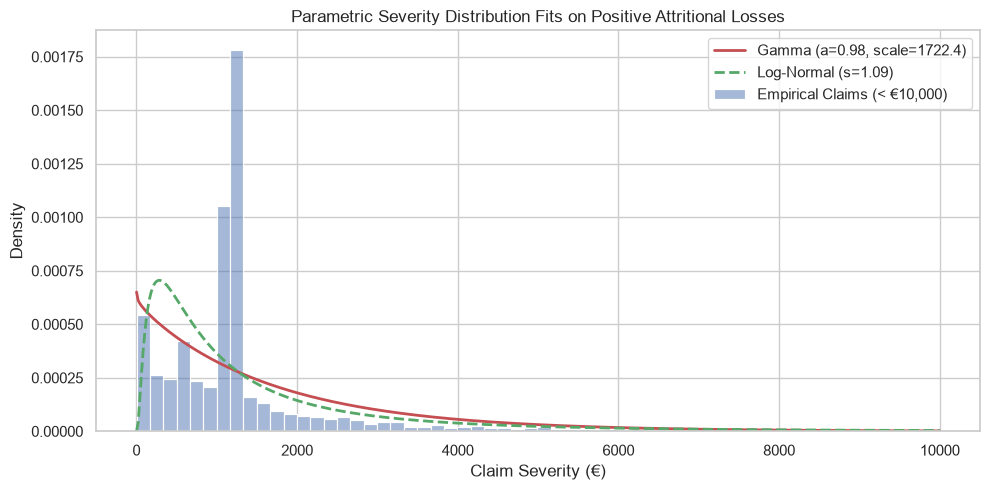

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(claims_data[claims_data < HIST_CAP], bins=HIST_BINS, stat="density", color="#4c72b0", alpha=0.5, label=f"Empirical Claims (< €{HIST_CAP:,})")

x = np.linspace(1, HIST_CAP, 500)
# Gamma fit
a, loc, scale = stats.gamma.fit(claims_data, floc=0)
plt.plot(x, stats.gamma.pdf(x, a, loc, scale), 'r-', lw=2, label=f"Gamma (a={a:.2f}, scale={scale:.1f})")

# Log-Normal fit
s, loc, scale_ln = stats.lognorm.fit(claims_data, floc=0)
plt.plot(x, stats.lognorm.pdf(x, s, loc, scale_ln), 'g--', lw=2, label=f"Log-Normal (s={s:.2f})")

plt.title("Parametric Severity Distribution Fits on Positive Attritional Losses", fontsize=12)
plt.xlabel("Claim Severity (€)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Hypothesis Testing & Effect Sizes

In [6]:
# 1. Fuel Type (VehGas) Hypothesis Test
contingency_gas = pd.crosstab(df["VehGas"], df["HasClaim"])
chi2_gas, p_gas, dof_gas, _ = stats.chi2_contingency(contingency_gas)
n = len(df)
cramers_v_gas = np.sqrt(chi2_gas / (n * (min(contingency_gas.shape) - 1)))

print("=== Hypothesis Test 1: Fuel Type (VehGas) vs Claim Occurrence ===")
print("H0: Claim occurrence is independent of fuel type (Diesel vs Regular).")
print("H1: Fuel type has a statistically significant association with claim frequency.")
print(f"Test: Chi-Square Test of Independence (dof={dof_gas})")
print(f"Result: Chi2 = {chi2_gas:.2f}, p-value = {p_gas:.2e}")
print(f"Effect Size: Cramer's V = {cramers_v_gas:.4f}")
_gas_rates = contingency_gas[1] / contingency_gas.sum(axis=1)
_gas_top = _gas_rates.idxmax()
print(f"Decision: {'Reject H0' if p_gas < 0.05 else 'Fail to reject H0'} (p-value = {p_gas:.2e}). {_gas_top} has the highest claim rate ({_gas_rates.max():.2%}).")

# 2. Geographic Area Hypothesis Test
contingency_area = pd.crosstab(df["Area"], df["HasClaim"])
chi2_area, p_area, dof_area, _ = stats.chi2_contingency(contingency_area)
cramers_v_area = np.sqrt(chi2_area / (n * (min(contingency_area.shape) - 1)))

print("\n=== Hypothesis Test 2: Territorial Area (Area A-F) vs Claim Occurrence ===")
print("H0: Claim occurrence is independent of geographic territory.")
print("H1: Geographic territory has a significant association with claim frequency.")
print(f"Test: Chi-Square Test of Independence (dof={dof_area})")
print(f"Result: Chi2 = {chi2_area:.2f}, p-value = {p_area:.2e}")
print(f"Effect Size: Cramer's V = {cramers_v_area:.4f}")
_area_rates = contingency_area[1] / contingency_area.sum(axis=1)
print(f"Decision: {'Reject H0' if p_area < 0.05 else 'Fail to reject H0'} (p-value = {p_area:.2e}). Highest: {_area_rates.idxmax()} ({_area_rates.max():.2%}); lowest: {_area_rates.idxmin()} ({_area_rates.min():.2%}).")

=== Hypothesis Test 1: Fuel Type (VehGas) vs Claim Occurrence ===
H0: Claim occurrence is independent of fuel type (Diesel vs Regular).
H1: Fuel type has a statistically significant association with claim frequency.
Test: Chi-Square Test of Independence (dof=1)
Result: Chi2 = 117.68, p-value = 2.04e-27
Effect Size: Cramer's V = 0.0132
Decision: Reject H0 (p-value = 2.04e-27). Regular has the highest claim rate (5.31%).

=== Hypothesis Test 2: Territorial Area (Area A-F) vs Claim Occurrence ===
H0: Claim occurrence is independent of geographic territory.
H1: Geographic territory has a significant association with claim frequency.
Test: Chi-Square Test of Independence (dof=5)
Result: Chi2 = 109.84, p-value = 4.43e-22
Effect Size: Cramer's V = 0.0127
Decision: Reject H0 (p-value = 4.43e-22). Highest: F (5.88%); lowest: A (4.65%).


## 5. Multicollinearity Assessment (VIF)

In [7]:
vif_features = ["DrivAge", "VehAge", "VehPower", "BonusMalus", "LogDensity"]
vif_df = compute_vif(df, vif_features)
print("=== Variance Inflation Factor (VIF) Analysis ===")
display(vif_df)

=== Variance Inflation Factor (VIF) Analysis ===


,Feature,VIF
0,BonusMalus,1.331506
1,DrivAge,1.300429
2,LogDensity,1.030021
3,VehAge,1.020418
4,VehPower,1.006065
